<a href="https://colab.research.google.com/github/aysesilainci/aysesilainci/blob/main/turkce_ner_berturk_vs_xlmr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Türkçe Adlandırılmış Varlık Tanıma (NER) – İki Modelin Karşılaştırması

**Görev:** Duygu analizi dışında bir NLU görevi olarak **Adlandırılmış Varlık Tanıma (Named Entity Recognition, NER)**.
Bir cümledeki her kelimeye `PER` (kişi), `ORG` (kurum) veya `LOC` (yer) etiketi (ya da `O` = varlık değil) atanır. Bu bir **token sınıflandırma** problemidir.

**Neden NER?** Türkçe sondan eklemeli (aglütinatif) bir dildir: `İstanbul'daki`, `Ankaralılar`, `Hacettepe Üniversitesi'nden` gibi biçimler tokenizer'ın alt-sözcük (subword) davranışını doğrudan etkiler. Bu yüzden tokenizer karşılaştırması NER'de çok anlamlı hale gelir.

**Akış**
1. Veri seti (WikiANN-tr) yükleme ve ön işleme
2. Model seçimi ve gerekçesi
3. Tokenizer analizi (iki tokenizer'ın Türkçe kelimeleri nasıl parçaladığı)
4. **Model 1:** `dbmdz/bert-base-turkish-cased` – standart tam ince ayar
5. Metrik: entity-düzeyi **seqeval** (precision / recall / F1) ve anlamı
6. Örnek metinler üzerinde çıktılar ve token düzeyi kararlar
7. **Model 2:** `FacebookAI/xlm-roberta-base` – farklı eğitim stratejisi (katman bazlı öğrenme oranı azaltımı + dondurulmuş embedding + cosine schedule)
8. Modeller ve tokenizer'ların karşılaştırılması, hata analizi

> **Çalıştırma notu:** GPU gerekir (Colab: *Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU*). Her iki eğitim T4'te toplam yaklaşık 15–25 dk sürer. Hızlı deneme için aşağıdaki `QUICK = True` yapılabilir.

## 0. Kurulum

In [ ]:
!pip install -q "transformers>=4.46" datasets evaluate seqeval accelerate matplotlib pandas

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os, re, time, random, warnings
from collections import Counter

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForTokenClassification,
                          DataCollatorForTokenClassification, TrainingArguments,
                          Trainer, pipeline, set_seed)
import evaluate
from seqeval.metrics import classification_report

warnings.filterwarnings("ignore")
SEED = 42
set_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Cihaz:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "GPU yok (çok yavaş olur)")

QUICK = False   # True: eğitim kümesini 2000 örneğe indirip hızlı deneme yapar
pd.set_option("display.max_colwidth", 80)

Cihaz: cuda | Tesla T4


## 1. Veri Seti: WikiANN (Türkçe)

**WikiANN** (Pan-X), Wikipedia makalelerinden otomatik olarak türetilmiş çok dilli bir NER veri setidir. Türkçe alt kümesi (`tr`) Hugging Face üzerinde `unimelb-nlp/wikiann` adıyla bulunur.

- Etiket şeması: **IOB2** → `O, B-PER, I-PER, B-ORG, I-ORG, B-LOC, I-LOC`
- Bölünmeler: train (20k), validation (10k), test (10k) cümle
- Not: Etiketler yarı-otomatik üretildiği için bir miktar gürültü içerir; bu, mutlak F1 değerlerinin neden "mükemmel" olmadığını açıklar.

In [ ]:
try:
    raw = load_dataset("unimelb-nlp/wikiann", "tr")
except Exception as e:
    print("Birincil ad başarısız, alternatif deneniyor:", e)
    raw = load_dataset("wikiann", "tr")

print(raw)
label_names = raw["train"].features["ner_tags"].feature.names
id2label = {i: l for i, l in enumerate(label_names)}
label2id = {l: i for i, l in id2label.items()}
print("\nEtiketler:", label_names)

README.md:   0%|          | 0.00/158k [00:00<?, ?B/s]

tr/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  729kB            

tr/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

tr/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  731kB            

tr/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

tr/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.45MB            

tr/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/20000 [00:00<?, ? examples/s]

DatasetDict({
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'langs', 'spans'],
        num_rows: 10000
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'langs', 'spans'],
        num_rows: 10000
    })
    train: Dataset({
        features: ['tokens', 'ner_tags', 'langs', 'spans'],
        num_rows: 20000
    })
})

Etiketler: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']


### 1.1 Ön işleme

Veri zaten kelimelere ayrılmış (`tokens`) ve kelime başına etiketlenmiş (`ner_tags`) geliyor. Yapılan adımlar:

1. Boş cümle, token/etiket sayısı uyuşmayan veya sadece boşluktan oluşan token içeren örnekleri **çıkar** (tokenizer'da 0 parça üretip hizalamayı bozabilirler).
2. Gereksiz sütunları (`langs`, `spans`) at.
3. **Sızıntı (leakage) kontrolü:** validation/test içinde birebir train'de de bulunan cümleleri çıkar; böylece ölçüm şişmez.
4. **Büyük/küçük harf korunur** (lowercase yapılmaz): Türkçe'de `İ/ı` ve büyük harf bilgisi özel isim tespiti için güçlü bir ipucudur.

In [ ]:
from datasets import DatasetDict

def is_ok(ex):
    return (len(ex["tokens"]) > 0
            and len(ex["tokens"]) == len(ex["ner_tags"])
            and all(t.strip() != "" for t in ex["tokens"]))

dsd = DatasetDict()
for split in ["train", "validation", "test"]:
    before = len(raw[split])
    d = raw[split].filter(is_ok).select_columns(["tokens", "ner_tags"])
    dsd[split] = d
    print(f"{split:<11} {before:>6} -> {len(d):>6}  (geçersiz elenen: {before-len(d)})")

# sızıntı kontrolü
train_sents = set(" ".join(t) for t in dsd["train"]["tokens"])
for split in ["validation", "test"]:
    before = len(dsd[split])
    dsd[split] = dsd[split].filter(lambda ex: " ".join(ex["tokens"]) not in train_sents)
    print(f"{split:<11} train ile örtüşen {before-len(dsd[split])} cümle çıkarıldı -> {len(dsd[split])}")

if QUICK:
    dsd["train"] = dsd["train"].shuffle(seed=SEED).select(range(2000))
    dsd["validation"] = dsd["validation"].select(range(1000))
    dsd["test"] = dsd["test"].select(range(1000))
    print("QUICK modu: küçültülmüş veri")

Filter:   0%|          | 0/20000 [00:00<?, ? examples/s]

train        20000 ->  20000  (geçersiz elenen: 0)


Filter:   0%|          | 0/10000 [00:00<?, ? examples/s]

validation   10000 ->  10000  (geçersiz elenen: 0)


Filter:   0%|          | 0/10000 [00:00<?, ? examples/s]

test         10000 ->  10000  (geçersiz elenen: 0)


Filter:   0%|          | 0/10000 [00:00<?, ? examples/s]

validation  train ile örtüşen 1265 cümle çıkarıldı -> 8735


Filter:   0%|          | 0/10000 [00:00<?, ? examples/s]

test        train ile örtüşen 1306 cümle çıkarıldı -> 8694


,train,validation,test
ORG,7970,3532,3542
PER,8833,3772,3891
LOC,9679,4700,4588


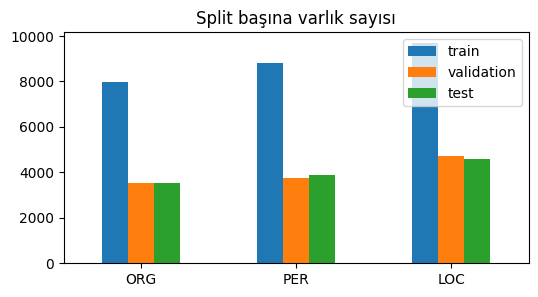

Cümle uzunluğu (kelime): ort=7.5, medyan=6.0, max=64
O etiketi oranı: 60.8%  -> doğruluk (accuracy) tek başına yanıltıcıdır!

Örnek:
kelime    San  Antonio  Spurs  (  Milwaukee'den  )
etiket  B-ORG    I-ORG  I-ORG  O              O  O


In [ ]:
# Varlık dağılımı ve cümle uzunluğu
def entity_counts(ds):
    c = Counter()
    for tags in ds["ner_tags"]:
        for t in tags:
            n = id2label[t]
            if n.startswith("B-"):
                c[n[2:]] += 1
    return c

dist = pd.DataFrame({s: entity_counts(dsd[s]) for s in dsd}).fillna(0).astype(int)
display(dist)
dist.plot(kind="bar", figsize=(6, 3), title="Split başına varlık sayısı"); plt.xticks(rotation=0); plt.show()

lens = [len(t) for t in dsd["train"]["tokens"]]
print(f"Cümle uzunluğu (kelime): ort={np.mean(lens):.1f}, medyan={np.median(lens)}, max={max(lens)}")
tag_total = Counter(t for tags in dsd["train"]["ner_tags"] for t in tags)
print("O etiketi oranı: %.1f%%  -> doğruluk (accuracy) tek başına yanıltıcıdır!" %
      (100 * tag_total[label2id['O']] / sum(tag_total.values())))

ex = dsd["train"][3]
print("\nÖrnek:")
print(pd.DataFrame({"kelime": ex["tokens"], "etiket": [id2label[t] for t in ex["ner_tags"]]}).T.to_string(header=False))

## 2. Model Seçimi ve Gerekçesi

NER, her token için bir sınıf tahmini gerektirir ve etiket kararı **hem sol hem sağ bağlama** bağlıdır (`Ankara` kelimesi *Ankara'da* ise LOC, *Ankara Üniversitesi'nde* ise ORG'un parçasıdır). Bu nedenle uygun mimari **çift yönlü (bidirectional) encoder-only Transformer**'dır (BERT ailesi) + token düzeyinde sınıflandırma başlığı (`AutoModelForTokenClassification`).

Decoder-only (GPT tipi) modeller soldan sağa bakar, encoder-decoder (T5) modeller ise etiketleme için gereksiz ağırdır; bu yüzden tercih edilmedi.

| | **Model 1** | **Model 2** |
|---|---|---|
| Model | `dbmdz/bert-base-turkish-cased` (BERTurk) | `FacebookAI/xlm-roberta-base` |
| Mimari | BERT-base (12 katman, 768 gizli boyut) | RoBERTa-base (12 katman, 768 gizli boyut) |
| Ön-eğitim derlemi | **Yalnızca Türkçe** (~35 GB: OSCAR, Wikipedia, OPUS, Kemal Oflazer derlemi) | **100 dil**, CC-100 (~2.5 TB; Türkçe bunun küçük bir parçası) |
| Ön-eğitim hedefi | MLM + NSP | Yalnızca MLM (daha uzun, daha büyük batch) |
| Tokenizer | WordPiece, ~32k Türkçe kelime hazinesi | SentencePiece (Unigram), 250k çok dilli kelime hazinesi |
| Eğitim stratejisi (bu notebook'ta) | Standart tam ince ayar | Katman bazlı LR azaltımı + dondurulmuş embedding + cosine |

**Gerekçe:** Model 1, Türkçe'ye özel bir kelime hazinesi ve derlemle eğitildiği için Türkçe için güçlü bir temel çizgidir. Model 2 ise çok dilli ve daha büyük derlemle eğitilmiş farklı bir aile olduğundan "dil-özel küçük derlem" ile "çok dilli büyük derlem" karşılaştırmasını mümkün kılar. Parametre sayısı benzer (gövde ~85M), dolayısıyla fark çoğunlukla **derlem, tokenizer ve eğitim stratejisinden** gelir.

In [ ]:
MODEL_1 = "dbmdz/bert-base-turkish-cased"
MODEL_2 = "FacebookAI/xlm-roberta-base"

tok1 = AutoTokenizer.from_pretrained(MODEL_1)
tok2 = AutoTokenizer.from_pretrained(MODEL_2)

for name, tk in [(MODEL_1, tok1), (MODEL_2, tok2)]:
    algo = tk.backend_tokenizer.model.__class__.__name__ if hasattr(tk, "backend_tokenizer") else "?"
    print(f"{name:<32} | sınıf={tk.__class__.__name__:<24} | algoritma={algo:<10} | kelime hazinesi={tk.vocab_size:,} | UNK={tk.unk_token}")

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/251k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

dbmdz/bert-base-turkish-cased    | sınıf=BertTokenizer            | algoritma=WordPiece  | kelime hazinesi=32,000 | UNK=[UNK]
FacebookAI/xlm-roberta-base      | sınıf=XLMRobertaTokenizer      | algoritma=Unigram    | kelime hazinesi=250,002 | UNK=<unk>


## 3. Tokenizer Analizi

Burada iki tokenizer'ın Türkçe kelimeleri nasıl parçaladığına bakıyoruz.

- **Fertility (verimlilik):** kelime başına ortalama alt-sözcük sayısı. 1.0 = hiç bölünmüyor. Yüksek fertility, daha uzun diziler ve bir kelimenin bilgisinin birçok parçaya dağılması demektir.
- **Bölünen kelime oranı:** 1'den fazla parçaya ayrılan kelimelerin yüzdesi.
- **UNK oranı:** bilinmeyen token oranı.

NER'de ek bir nokta: etiket **yalnızca kelimenin ilk alt-sözcüğüne** verilir (diğerleri eğitimde `-100` ile yok sayılır).

In [ ]:
def show_tokenization(words, tokenizers):
    rows = []
    for w in words:
        row = {"kelime": w}
        for label, tk in tokenizers.items():
            row[label] = " | ".join(tk.tokenize(w)) + f"   ({len(tk.tokenize(w))})"
        rows.append(row)
    return pd.DataFrame(rows)

demo_words = ["Ankara", "İstanbul'daki", "Çanakkale'ye", "Ankaralılar", "Hacettepe", "Üniversitesi'nden",
              "Atatürk", "Büyükşehir", "Gaziantep'te", "Ankaralılaştıramadıklarımızdan", "Beşiktaş", "Schwarzenegger'in"]
tok_table = show_tokenization(demo_words, {"BERTurk (WordPiece)": tok1, "XLM-R (SentencePiece)": tok2})
display(tok_table)

,kelime,BERTurk (WordPiece),XLM-R (SentencePiece)
0,Ankara,Ankara (1),▁Ankara (1)
1,İstanbul'daki,İstanbul | ' | daki (3),▁İstanbul | ' | daki (3)
2,Çanakkale'ye,Çanakkale | ' | ye (3),▁Çanakkale | ' | ye (3)
3,Ankaralılar,Ankara | ##lılar (2),▁Ankara | lılar (2)
4,Hacettepe,Hacettepe (1),▁Hace | t | tepe (3)
5,Üniversitesi'nden,Üniversitesi | ' | nden (3),▁Üniversitesi | ' | nden (3)
6,Atatürk,Atatürk (1),▁Atatürk (1)
7,Büyükşehir,Büyükşehir (1),▁Büyükşehir (1)
8,Gaziantep'te,Gaziantep | ' | te (3),▁Gaziantep | ' | te (3)
9,Ankaralılaştıramadıklarımızdan,Ankara | ##lı | ##laştır | ##amadı | ##k | ##larımızdan (6),▁Ankara | lı | laştı | rama | dıkları | mızda | n (7)


,Fertility (tüm kelimeler),Fertility (varlık kelimeleri),Fertility (varlık olmayan),Bölünen kelime %,UNK %,Cümle başına ort. token
Tokenizer,,,,,,
BERTurk,1.638,1.970,1.439,38.361,0.045,14.916
XLM-R,1.759,1.864,1.695,48.121,0.001,15.865


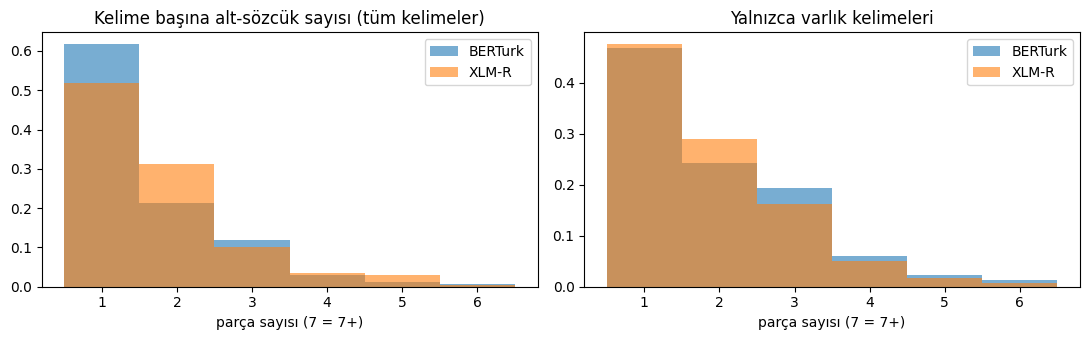

In [ ]:
def piece_stats(tok, ds):
    # dsd["tokens"] yapısını garanti altına almak için list'e dönüştürüyoruz
    toks = list(ds["tokens"])
    tags = list(ds["ner_tags"])
    enc = tok(toks, is_split_into_words=True, truncation=False, add_special_tokens=False)
    rows = []
    unk = tok.unk_token_id
    for i in range(len(toks)):
        wids = enc.word_ids(i); ids = enc["input_ids"][i]
        cnt, cu = Counter(wids), Counter(w for w, t in zip(wids, ids) if t == unk)
        for w, (word, tag) in enumerate(zip(toks[i], tags[i])):
            rows.append((i, w, word, tag, cnt.get(w, 0), cu.get(w, 0)))
    df = pd.DataFrame(rows, columns=["sent", "widx", "word", "tag", "n_pieces", "n_unk"])
    df["is_entity"] = df["tag"] > 0
    return df

stats = {"BERTurk": piece_stats(tok1, dsd["validation"]),
         "XLM-R": piece_stats(tok2, dsd["validation"])}

summary = []
for k, df in stats.items():
    summary.append({
        "Tokenizer": k,
        "Fertility (tüm kelimeler)": df.n_pieces.mean(),
        "Fertility (varlık kelimeleri)": df[df.is_entity].n_pieces.mean(),
        "Fertility (varlık olmayan)": df[~df.is_entity].n_pieces.mean(),
        "Bölünen kelime %": 100 * (df.n_pieces > 1).mean(),
        "UNK %": 100 * df.n_unk.sum() / df.n_pieces.sum(),
        "Cümle başına ort. token": df.groupby("sent").n_pieces.sum().mean() + 2,
    })
tok_summary = pd.DataFrame(summary).set_index("Tokenizer").round(3)
display(tok_summary)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
bins = range(1, 8)
for k, df in stats.items():
    ax[0].hist(df.n_pieces.clip(upper=7), bins=bins, alpha=.6, label=k, density=True, align="left")
    ax[1].hist(df[df.is_entity].n_pieces.clip(upper=7), bins=bins, alpha=.6, label=k, density=True, align="left")
ax[0].set_title("Kelime başına alt-sözcük sayısı (tüm kelimeler)"); ax[1].set_title("Yalnızca varlık kelimeleri")
for a in ax: a.set_xlabel("parça sayısı (7 = 7+)"); a.legend()
plt.tight_layout(); plt.show()

In [ ]:
# Gerçek bir veri seti cümlesi üzerinde: kelime | gerçek etiket | iki tokenizer'ın parçaları
i = next(i for i, t in enumerate(dsd["validation"]["ner_tags"])
         if sum(x > 0 for x in t) >= 3 and len(t) <= 12)
sent = dsd["validation"][i]
rows = []
for w, t in zip(sent["tokens"], sent["ner_tags"]):
    rows.append({"kelime": w, "etiket": id2label[t],
                 "BERTurk": " ".join(tok1.tokenize(w)), "XLM-R": " ".join(tok2.tokenize(w))})
display(pd.DataFrame(rows))
print("BERTurk tam dizi :", tok1.convert_ids_to_tokens(tok1(sent["tokens"], is_split_into_words=True)["input_ids"]))
print("XLM-R   tam dizi :", tok2.convert_ids_to_tokens(tok2(sent["tokens"], is_split_into_words=True)["input_ids"]))

,kelime,etiket,BERTurk,XLM-R
0,Yıldız,B-ORG,Yıldız,▁Yıldız
1,Savaşları,I-ORG,Savaş ##ları,▁Savaş ları
2,:,I-ORG,:,▁:
3,Bölüm,I-ORG,Bölüm,▁Bölüm
4,II,I-ORG,II,▁II
5,-,I-ORG,-,▁-
6,Klonların,I-ORG,K ##lon ##ların,▁Klo n ların
7,Saldırısı,I-ORG,Saldırı ##sı,▁Sal dır ısı
8,'',O,' ',▁''


BERTurk tam dizi : ['[CLS]', 'Yıldız', 'Savaş', '##ları', ':', 'Bölüm', 'II', '-', 'K', '##lon', '##ların', 'Saldırı', '##sı', "'", "'", '[SEP]']
XLM-R   tam dizi : ['<s>', '▁Yıldız', '▁Savaş', 'ları', '▁:', '▁Bölüm', '▁II', '▁-', '▁Klo', 'n', 'ların', '▁Sal', 'dır', 'ısı', "▁''", '</s>']


**Okuma rehberi:** BERTurk alt-sözcükleri `##` öneki ile işaretler (kelime ortası/sonu), XLM-R ise kelime başını `▁` ile işaretler. Türkçe'ye özel kelime hazinesi genellikle kökü ve sık ekleri daha tutarlı parçalar; çok dilli 250k'lık kelime hazinesi ise Türkçe için daha dağınık bölmeler üretebilir. Kesin yorumu yukarıdaki **fertility tablosundaki** sayılara göre yapın.

## 4. Girdi Hazırlama: Alt-Sözcük–Etiket Hizalaması

Etiketler kelime düzeyinde, model girdisi ise alt-sözcük düzeyindedir. Strateji:

- Her kelimenin **ilk alt-sözcüğü** gerçek etiketi alır.
- Kelimenin kalan alt-sözcükleri ve özel tokenlar (`[CLS]`, `[SEP]`, `<s>`, `</s>`) `-100` alır → kayıp (loss) hesabında yok sayılır.
- Tahminde de yalnızca ilk alt-sözcük pozisyonları değerlendirilir; böylece değerlendirme **kelime düzeyinde** kalır ve iki tokenizer adil karşılaştırılır.

In [ ]:
MAX_LEN = 128

def make_tokenized(tok):
    def f(batch):
        enc = tok(batch["tokens"], is_split_into_words=True, truncation=True, max_length=MAX_LEN)
        all_labels = []
        for i, tags in enumerate(batch["ner_tags"]):
            prev, lab = None, []
            for w in enc.word_ids(i):
                if w is None:      lab.append(-100)
                elif w != prev:    lab.append(tags[w])
                else:              lab.append(-100)
                prev = w
            all_labels.append(lab)
        enc["labels"] = all_labels
        return enc
    return dsd.map(f, batched=True, remove_columns=dsd["train"].column_names, desc="tokenize")

tokd1 = make_tokenized(tok1)
tokd2 = make_tokenized(tok2)
print(tokd1)

k = 0
print("\nHizalama örneği (BERTurk):")
toks = tok1.convert_ids_to_tokens(tokd1["train"][k]["input_ids"])
print(pd.DataFrame({"token": toks, "label_id": tokd1["train"][k]["labels"],
                    "etiket": [id2label.get(l, "—(-100)") for l in tokd1["train"][k]["labels"]]}).T.to_string(header=False))

tokenize:   0%|          | 0/20000 [00:00<?, ? examples/s]

tokenize:   0%|          | 0/8735 [00:00<?, ? examples/s]

tokenize:   0%|          | 0/8694 [00:00<?, ? examples/s]

tokenize:   0%|          | 0/20000 [00:00<?, ? examples/s]

tokenize:   0%|          | 0/8735 [00:00<?, ? examples/s]

tokenize:   0%|          | 0/8694 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 20000
    })
    validation: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 8735
    })
    test: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 8694
    })
})

Hizalama örneği (BERTurk):
token       [CLS]  3        .      lük  maçında  Slovenya  Millî  Basketbol  Takımı        '       nı  yendi      ##k   ##leri  maçta  23  sayı  ,  6  riba    ##und  ,  2  blok  istatistikleri    ##yle  oynamış  ve  12  faul  yaptır  ##mıştır  .    [SEP]
label_id     -100  0     -100     -100        0         3      4          4       4     -100     -100      0     -100     -100      0   0     0  0  0     0     -100  0  0     0               0     -100        0   0   0     0       0      -100  0     -100
etiket    —(-100)  O  —(-100)  —(-100)        O   

## 5. Değerlendirme Metriği: Entity-Düzeyi F1 (seqeval)

**Neden token accuracy değil?** Veri setinin ~%80'i `O` etiketidir. Her şeye `O` diyen bir model bile yüksek accuracy alır. Bu yüzden NER'de standart metrik, **varlık düzeyinde (entity-level) tam eşleşme** ölçen **seqeval** çıktısıdır.

Bir varlık tahmini ancak **hem sınırları (başlangıç–bitiş) hem tipi** gerçek etiketle birebir aynıysa doğru sayılır:
- Gerçek: `[Mustafa Kemal Atatürk]PER` — Tahmin: `[Kemal Atatürk]PER` → **yanlış** (sınır hatası, hem FP hem FN)
- Gerçek: `[Ankara]LOC` — Tahmin: `[Ankara]ORG` → **yanlış** (tip hatası)

Tanımlar (varlık sayıları üzerinden):

- **Precision** = doğru tahmin edilen varlık / tahmin edilen tüm varlıklar → "söylediklerinin ne kadarı doğru?"
- **Recall** = doğru tahmin edilen varlık / gerçekte olan tüm varlıklar → "gerçek varlıkların ne kadarını yakaladı?"
- **F1** = 2·P·R / (P+R) → ikisinin harmonik ortalaması. Raporlanan **overall F1 mikro-ortalamadır** (tüm varlıklar birlikte sayılır); tip bazında F1 de ayrıca verilir.

Model seçimi (`load_best_model_at_end`) ve karşılaştırma için ana ölçüt **validation F1**, nihai rapor **test F1**'dir.

In [ ]:
seqeval = evaluate.load("seqeval")

def to_labels(preds, labels):
    p = np.argmax(preds, axis=-1)
    tp, tl = [], []
    for pi, li in zip(p, labels):
        m = li != -100
        tp.append([id2label[int(x)] for x in pi[m]])
        tl.append([id2label[int(x)] for x in li[m]])
    return tp, tl

def compute_metrics(eval_pred):
    preds, labels = eval_pred
    tp, tl = to_labels(preds, labels)
    r = seqeval.compute(predictions=tp, references=tl)
    return {"precision": r["overall_precision"], "recall": r["overall_recall"],
            "f1": r["overall_f1"], "accuracy": r["overall_accuracy"]}

## 6. Eğitim Yardımcıları

İki farklı strateji aynı fonksiyonla yönetilir:

**Strateji A (Model 1) – Standart tam ince ayar:** tüm parametreler eğitilir, tek öğrenme oranı (`3e-5`), lineer azalan schedule, 3 epoch.

**Strateji B (Model 2) – Katmanlı/seçici ince ayar:**
- **Katman bazlı öğrenme oranı azaltımı (LLRD):** üst katmanlar/sınıflandırıcı yüksek LR, alt katmanlar `0.9^k` ile azalan LR. Alt katmanlar genel dil bilgisini tutar, üst katmanlar göreve uyum sağlar.
- **Dondurulmuş embedding:** XLM-R'in 250k × 768'lik embedding matrisi (~192M parametre) eğitim dışı bırakılır → bellek/hız kazancı ve çok dilli temsilleri bozma riskinin azalması.
- **Cosine LR schedule**, 4 epoch, daha yüksek taban LR (`6e-5`).

In [ ]:
def build_llrd_optimizer(model, base_lr, decay, wd):
    n_layers = model.config.num_hidden_layers
    no_decay = ("bias", "LayerNorm.weight", "LayerNorm.bias", "layer_norm")
    groups = []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        m = re.search(r"layer\.(\d+)\.", name)
        if m:                      lr = base_lr * decay ** (n_layers - 1 - int(m.group(1)))
        elif "embeddings" in name: lr = base_lr * decay ** n_layers
        else:                      lr = base_lr          # sınıflandırıcı başlığı
        w = 0.0 if any(nd in name for nd in no_decay) else wd
        groups.append({"params": [p], "lr": lr, "weight_decay": w})
    return torch.optim.AdamW(groups, lr=base_lr)

def count_params(model):
    tot = sum(p.numel() for p in model.parameters())
    tr = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return tot, tr

def run_experiment(tag, model_name, tok, tokenized, lr, epochs, scheduler="linear",
                   llrd=None, freeze_emb=False, bs=32, wd=0.01, warmup=0.1):
    set_seed(SEED)
    model = AutoModelForTokenClassification.from_pretrained(
        model_name, num_labels=len(label_names), id2label=id2label, label2id=label2id)
    if freeze_emb:
        for p in model.base_model.embeddings.parameters():
            p.requires_grad = False
    total, trainable = count_params(model)
    print(f"[{tag}] toplam parametre: {total/1e6:.1f}M | eğitilen: {trainable/1e6:.1f}M")

    args = TrainingArguments(
        output_dir=f"out_{tag}", num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=bs, per_device_eval_batch_size=64,
        weight_decay=wd, warmup_ratio=warmup, lr_scheduler_type=scheduler,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="f1", greater_is_better=True,
        logging_steps=50, fp16=torch.cuda.is_available(), report_to="none", seed=SEED)

    optimizers = (build_llrd_optimizer(model, lr, llrd, wd), None) if llrd else (None, None)
    trainer = Trainer(model=model, args=args,
                      train_dataset=tokenized["train"], eval_dataset=tokenized["validation"],
                      data_collator=DataCollatorForTokenClassification(tok),
                      processing_class=tok, compute_metrics=compute_metrics, optimizers=optimizers)
    t0 = time.time()
    trainer.train()
    elapsed = time.time() - t0
    return trainer, {"total_params": total, "trainable_params": trainable, "train_min": elapsed / 60}

def full_eval(trainer, tokenized_split):
    out = trainer.predict(tokenized_split)
    tp, tl = to_labels(out.predictions, out.label_ids)
    return seqeval.compute(predictions=tp, references=tl), tp, tl

def plot_curves(trainer, title):
    h = pd.DataFrame(trainer.state.log_history)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    tr = h.dropna(subset=["loss"]); ev = h.dropna(subset=["eval_f1"])
    ax[0].plot(tr["step"], tr["loss"]); ax[0].set_title(f"{title} – eğitim kaybı"); ax[0].set_xlabel("adım")
    ax[1].plot(ev["epoch"], ev["eval_f1"], marker="o", label="val F1")
    ax[1].plot(ev["epoch"], ev["eval_precision"], marker=".", ls="--", label="val P")
    ax[1].plot(ev["epoch"], ev["eval_recall"], marker=".", ls="--", label="val R")
    ax[1].set_title(f"{title} – doğrulama"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

## 7. Model 1 – BERTurk, standart tam ince ayar

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-base-turkish-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those param

[berturk] toplam parametre: 110.0M | eğitilen: 110.0M


Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.148618,0.120888,0.886851,0.906281,0.896461,0.965602
2,0.098080,0.117758,0.902094,0.914945,0.908474,0.968056
3,0.064245,0.121411,0.908957,0.922359,0.915609,0.969682


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

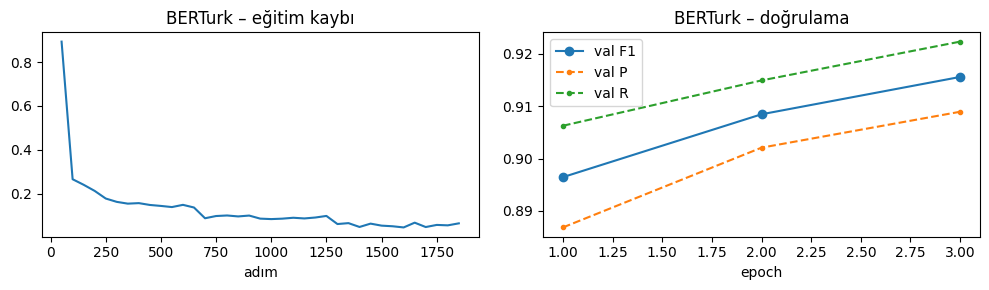

In [ ]:
# warmup_ratio parametresini TrainingArguments içerisinden kaldırarak çalıştıran güvenli fonksiyonu tanımlıyoruz
def run_experiment_fixed(tag, model_name, tok, tokenized, lr, epochs, scheduler="linear",
                         llrd=None, freeze_emb=False, bs=32, wd=0.01):
    set_seed(SEED)
    model = AutoModelForTokenClassification.from_pretrained(
        model_name, num_labels=len(label_names), id2label=id2label, label2id=label2id)
    if freeze_emb:
        for p in model.base_model.embeddings.parameters():
            p.requires_grad = False
    total, trainable = count_params(model)
    print(f"[{tag}] toplam parametre: {total/1e6:.1f}M | eğitilen: {trainable/1e6:.1f}M")

    args = TrainingArguments(
        output_dir=f"out_{tag}", num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=bs, per_device_eval_batch_size=64,
        weight_decay=wd, lr_scheduler_type=scheduler,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="f1", greater_is_better=True,
        logging_steps=50, fp16=torch.cuda.is_available(), report_to="none", seed=SEED)

    optimizers = (build_llrd_optimizer(model, lr, llrd, wd), None) if llrd else (None, None)
    trainer = Trainer(model=model, args=args,
                      train_dataset=tokenized["train"], eval_dataset=tokenized["validation"],
                      data_collator=DataCollatorForTokenClassification(tok),
                      processing_class=tok, compute_metrics=compute_metrics, optimizers=optimizers)
    t0 = time.time()
    trainer.train()
    elapsed = time.time() - t0
    return trainer, {"total_params": total, "trainable_params": trainable, "train_min": elapsed / 60}

trainer1, info1 = run_experiment_fixed("berturk", MODEL_1, tok1, tokd1,
                                       lr=3e-5, epochs=3, scheduler="linear")
plot_curves(trainer1, "BERTurk")

In [ ]:
res1, tp1, tl1 = full_eval(trainer1, tokd1["test"])
print("=== BERTurk – TEST (entity-düzeyi, seqeval) ===")
print(classification_report(tl1, tp1, digits=4))
print(f"Overall  P={res1['overall_precision']:.4f}  R={res1['overall_recall']:.4f}  F1={res1['overall_f1']:.4f}  token-acc={res1['overall_accuracy']:.4f}")

=== BERTurk – TEST (entity-düzeyi, seqeval) ===
              precision    recall  f1-score   support

         LOC     0.9074    0.9252    0.9163      4588
         ORG     0.8718    0.8659    0.8688      3542
         PER     0.9302    0.9450    0.9375      3891

   micro avg     0.9045    0.9142    0.9093     12021
   macro avg     0.9031    0.9120    0.9075     12021
weighted avg     0.9043    0.9142    0.9092     12021

Overall  P=0.9045  R=0.9142  F1=0.9093  token-acc=0.9695


### 7.1 Model 1 – örnek metinler üzerinde çıktılar

Önce `pipeline` ile varlık düzeyinde (kelime parçaları birleştirilmiş) çıktı, sonra **token düzeyinde** kararlar: her alt-sözcük için tahmin edilen etiket ve güven skoru. Böylece tokenizer'ın bölmesi ile modelin kararı yan yana görülebilir.

In [ ]:
samples = [
    "Mustafa Kemal Atatürk 1881 yılında Selanik'te doğdu.",
    "Türkiye Büyük Millet Meclisi Ankara'da toplandı.",
    "Hacettepe Üniversitesi'nden mezun olan Ayşe Yılmaz, Google'ın İstanbul ofisinde çalışıyor.",
    "Orhan Pamuk, Nobel Edebiyat Ödülü'nü aldıktan sonra Beşiktaş'taki evine döndü.",
    "Fenerbahçe, Galatasaray'ı Kadıköy'deki Ülker Stadyumu'nda yendi.",
]

def make_pipe(trainer, tok):
    m = trainer.model.eval()
    return pipeline("token-classification", model=m, tokenizer=tok, aggregation_strategy="simple",
                    device=0 if torch.cuda.is_available() else -1)

def annotate(text, ents):
    out, last = "", 0
    for e in sorted(ents, key=lambda x: x["start"]):
        out += text[last:e["start"]] + f"[{text[e['start']:e['end']]} | {e['entity_group']} {e['score']:.2f}]"
        last = e["end"]
    return out + text[last:]

def token_level(text, trainer, tok):
    model = trainer.model.eval()
    enc = tok(text, return_tensors="pt", return_offsets_mapping=True, truncation=True, max_length=MAX_LEN)
    offs = enc.pop("offset_mapping")[0].tolist()
    enc = {k: v.to(model.device) for k, v in enc.items()}
    with torch.no_grad():
        probs = torch.softmax(model(**enc).logits[0], -1).cpu()
    toks = tok.convert_ids_to_tokens(enc["input_ids"][0].tolist())
    rows = []
    for t, (s, e), p in zip(toks, offs, probs):
        if s == e:   # özel tokenlar
            continue
        k = int(p.argmax())
        rows.append({"token": t, "tahmin": id2label[k], "güven": round(float(p[k]), 3)})
    return pd.DataFrame(rows)

pipe1 = make_pipe(trainer1, tok1)
for s in samples:
    print("•", annotate(s, pipe1(s)))

• [Mustafa Kemal Atatürk | PER 1.00] 1881 yılında [Selanik | LOC 1.00]'te doğdu.
• [Türkiye Büyük Millet Meclisi | ORG 1.00] [Ankara | LOC 1.00]'da toplandı.
• [Hacettepe Üniversitesi | ORG 1.00]'nden mezun olan [Ayşe Yılmaz | PER 0.69], [Google | ORG 0.99]'ın [İstanbul | LOC 0.89] ofisinde çalışıyor.
• [Orhan Pamuk | PER 1.00], Nobel [Edebiyat | ORG 0.51] Ödülü'nü aldıktan sonra [Beşiktaş | LOC 0.99]'taki evine döndü.
• [Fenerbahçe | ORG 1.00], [Galatasaray | ORG 0.99]'ı [Kadıköy | LOC 0.99]'deki [Ülker Stadyumu | ORG 0.93]'nda yendi.


In [ ]:
print("Token düzeyi kararlar – BERTurk")
display(token_level(samples[2], trainer1, tok1).T)

Token düzeyi kararlar – BERTurk


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
token,Hacettepe,Üniversitesi,',nden,mezun,olan,Ayşe,Yılmaz,",",Google,',ın,İstanbul,ofisi,##nde,çalışıyor,.
tahmin,B-ORG,I-ORG,O,O,O,O,B-PER,I-PER,O,B-ORG,O,O,B-LOC,O,O,O,O
güven,0.996,0.995,0.996,0.995,1.0,1.0,0.59,0.79,1.0,0.994,0.882,0.966,0.89,0.999,1.0,1.0,1.0


## 8. Model 2 – XLM-RoBERTa, farklı strateji ve farklı derlem

Aynı veri, aynı seed, ama:
- **Farklı ön-eğitim derlemi:** CC-100 (100 dil)
- **Farklı tokenizer:** SentencePiece, 250k kelime hazinesi
- **Farklı eğitim stratejisi:** LLRD (`0.9`) + dondurulmuş embedding + cosine schedule + 4 epoch + `6e-5`

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[xlmr] toplam parametre: 277.5M | eğitilen: 85.1M


Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.174621,0.139670,0.867437,0.894535,0.880778,0.959939
2,0.123419,0.121941,0.897033,0.909364,0.903156,0.965979
3,0.086723,0.119197,0.908409,0.917944,0.913152,0.968971
4,0.054536,0.125060,0.906786,0.920610,0.913646,0.969435


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

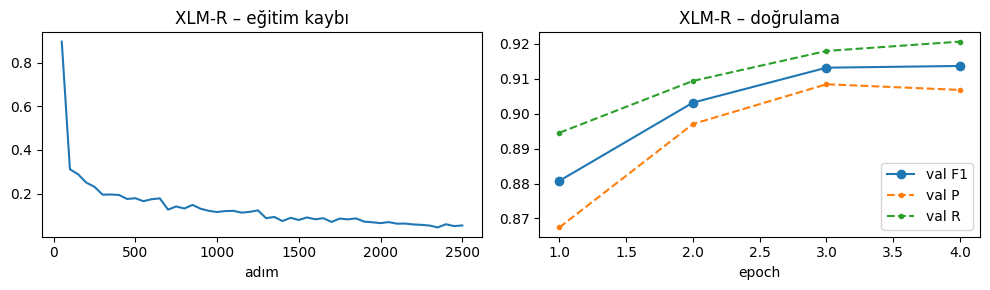

In [ ]:
# warmup_ratio parametresini TrainingArguments içerisinden kaldırarak çalıştıran güvenli fonksiyonu tanımlıyoruz
def run_experiment_fixed2(tag, model_name, tok, tokenized, lr, epochs, scheduler="linear",
                          llrd=None, freeze_emb=False, bs=32, wd=0.01):
    set_seed(SEED)
    model = AutoModelForTokenClassification.from_pretrained(
        model_name, num_labels=len(label_names), id2label=id2label, label2id=label2id)
    if freeze_emb:
        for p in model.base_model.embeddings.parameters():
            p.requires_grad = False
    total, trainable = count_params(model)
    print(f"[{tag}] toplam parametre: {total/1e6:.1f}M | eğitilen: {trainable/1e6:.1f}M")

    args = TrainingArguments(
        output_dir=f"out_{tag}", num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=bs, per_device_eval_batch_size=64,
        weight_decay=wd, lr_scheduler_type=scheduler,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="f1", greater_is_better=True,
        logging_steps=50, fp16=torch.cuda.is_available(), report_to="none", seed=SEED)

    optimizers = (build_llrd_optimizer(model, lr, llrd, wd), None) if llrd else (None, None)
    trainer = Trainer(model=model, args=args,
                      train_dataset=tokenized["train"], eval_dataset=tokenized["validation"],
                      data_collator=DataCollatorForTokenClassification(tok),
                      processing_class=tok, compute_metrics=compute_metrics, optimizers=optimizers)
    t0 = time.time()
    trainer.train()
    elapsed = time.time() - t0
    return trainer, {"total_params": total, "trainable_params": trainable, "train_min": elapsed / 60}

trainer2, info2 = run_experiment_fixed2("xlmr", MODEL_2, tok2, tokd2,
                                        lr=6e-5, epochs=4, scheduler="cosine",
                                        llrd=0.9, freeze_emb=True)
plot_curves(trainer2, "XLM-R")

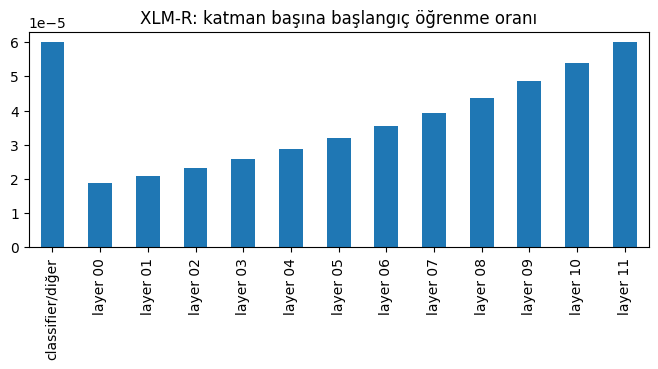

In [ ]:
# Katman bazlı öğrenme oranlarının gerçekten uygulandığını görelim
opt = trainer2.optimizer
lr_by_layer = {}
for g, (name, p) in zip(opt.param_groups, [(n, p) for n, p in trainer2.model.named_parameters() if p.requires_grad]):
    m = re.search(r"layer\.(\d+)\.", name)
    key = f"layer {int(m.group(1)):02d}" if m else "classifier/diğer"
    lr_by_layer[key] = g["initial_lr"] if "initial_lr" in g else g["lr"]
pd.Series(lr_by_layer).sort_index().plot(kind="bar", figsize=(8, 2.8), title="XLM-R: katman başına başlangıç öğrenme oranı"); plt.show()

In [ ]:
res2, tp2, tl2 = full_eval(trainer2, tokd2["test"])
print("=== XLM-R – TEST (entity-düzeyi, seqeval) ===")
print(classification_report(tl2, tp2, digits=4))
print(f"Overall  P={res2['overall_precision']:.4f}  R={res2['overall_recall']:.4f}  F1={res2['overall_f1']:.4f}  token-acc={res2['overall_accuracy']:.4f}")

=== XLM-R – TEST (entity-düzeyi, seqeval) ===
              precision    recall  f1-score   support

         LOC     0.9021    0.9296    0.9156      4588
         ORG     0.8829    0.8710    0.8769      3542
         PER     0.9301    0.9435    0.9367      3891

   micro avg     0.9057    0.9168    0.9112     12021
   macro avg     0.9050    0.9147    0.9098     12021
weighted avg     0.9055    0.9168    0.9110     12021

Overall  P=0.9057  R=0.9168  F1=0.9112  token-acc=0.9690


In [ ]:
pipe2 = make_pipe(trainer2, tok2)
print("Model 2 (XLM-R) örnek çıktılar:")
for s in samples:
    print("•", annotate(s, pipe2(s)))
print("\nToken düzeyi kararlar – XLM-R")
display(token_level(samples[2], trainer2, tok2).T)

Model 2 (XLM-R) örnek çıktılar:
• [Mustafa Kemal Atatürk | PER 1.00] 1881 yılında [Selanik | LOC 0.97]'te doğdu.
• [Türkiye Büyük Millet Meclisi | ORG 0.99] [Ankara | LOC 1.00]'da toplandı.
• [Hacettepe Üniversitesi | ORG 0.98]'nden mezun olan [Ayşe Yılmaz | PER 1.00], [Google | ORG 0.94]'ın [İstanbul | LOC 0.99] ofisinde çalışıyor.
• [Orhan Pamuk | PER 1.00], [Nobel Edebiyat Ödülü | ORG 0.84]'nü aldıktan sonra [Beşiktaş | LOC 0.97]'taki evine döndü.
• [Fenerbahçe | ORG 0.99], [Galatasaray | ORG 0.99]'ı [Kadıköy | LOC 0.93]'deki [Ülker Stadyumu | ORG 0.90]'nda yendi.

Token düzeyi kararlar – XLM-R


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
token,▁Hace,t,tepe,▁Üniversitesi,',nden,▁mezun,▁olan,▁Ayşe,▁Yılmaz,",",▁Google,',ın,▁İstanbul,▁ofisi,nde,▁çalışıyor,.
tahmin,B-ORG,I-ORG,I-ORG,I-ORG,O,O,O,O,B-PER,I-PER,O,B-ORG,O,O,B-LOC,O,O,O,O
güven,0.998,0.939,0.994,0.998,0.969,1.0,1.0,1.0,0.995,0.998,1.0,0.944,0.916,0.992,0.994,0.999,1.0,1.0,1.0


## 9. Karşılaştırma

Model,BERTurk,XLM-R base
Ön-eğitim derlemi,Türkçe (~35GB),Türkçe (~35GB)
Tokenizer,"WordPiece / 32,000","Unigram / 250,002"
Strateji,"Tam ince ayar, lineer LR",LLRD + donuk embedding + cosine
Epoch,3,4
Eğitilen param (M),110.0,85.1
Eğitim süresi (dk),5.0,8.0
Val F1 (en iyi),0.9156,0.9136
Test Precision,0.9045,0.9057
Test Recall,0.9142,0.9168
Test F1,0.9093,0.9112


,BERTurk,XLM-R
PER,0.9375,0.9367
ORG,0.8688,0.8769
LOC,0.9163,0.9156


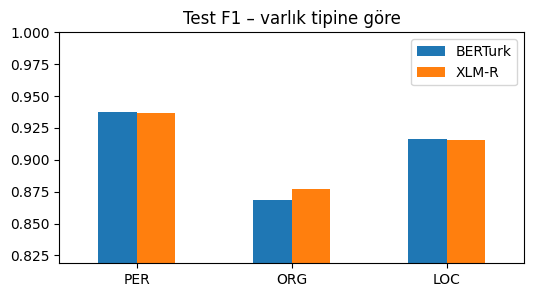

In [ ]:
def row(name, model_name, tk, tr, info, res, strategy, epochs):
    df = stats["BERTurk" if "bert" in model_name else "XLM-R"]
    best_val = max(h["eval_f1"] for h in tr.state.log_history if "eval_f1" in h)
    return {
        "Model": name, "Ön-eğitim derlemi": "Türkçe (~35GB)" if "bert" in model_name else "CC-100, 100 dil (~2.5TB)",
        "Tokenizer": f"{tk.backend_tokenizer.model.__class__.__name__} / {tk.vocab_size:,}",
        "Strateji": strategy, "Epoch": epochs,
        "Eğitilen param (M)": round(info["trainable_params"] / 1e6, 1),
        "Eğitim süresi (dk)": round(info["train_min"], 1),
        "Val F1 (en iyi)": round(best_val, 4),
        "Test Precision": round(res["overall_precision"], 4),
        "Test Recall": round(res["overall_recall"], 4),
        "Test F1": round(res["overall_f1"], 4),
        "Token acc.": round(res["overall_accuracy"], 4),
        "Fertility": round(df.n_pieces.mean(), 3),
    }

cmp = pd.DataFrame([
    row("BERTurk", MODEL_1, tok1, trainer1, info1, res1, "Tam ince ayar, lineer LR", 3),
    row("XLM-R base", MODEL_2, tok2, trainer2, info2, res2, "LLRD + donuk embedding + cosine", 4),
]).set_index("Model")
display(cmp.T)

# Tip bazında F1
types = ["PER", "ORG", "LOC"]
per_type = pd.DataFrame({"BERTurk": [res1[t]["f1"] for t in types],
                         "XLM-R": [res2[t]["f1"] for t in types]}, index=types)
display(per_type.round(4))
ax = per_type.plot(kind="bar", figsize=(6, 3), ylim=(per_type.values.min() - .05, 1), title="Test F1 – varlık tipine göre")
plt.xticks(rotation=0); plt.show()

### 9.1 Tokenizer parçalanması performansı nasıl etkiliyor?

Varlık kelimelerini, **kaç alt-sözcüğe bölündüklerine** göre gruplayıp kelime düzeyinde etiket doğruluğuna bakıyoruz (yalnızca gerçek etiketi `O` olmayan kelimeler). Çok parçalı kelimelerde doğruluk düşüyorsa, bölünme sorunun parçası olabilir.

BERTurk         XLM-R       
      mean  count   mean  count
1    0.932  11606  0.939  11842
2    0.937   6283  0.931   7379
3    0.938   4985  0.927   4157
4+   0.905   2550  0.912   2046

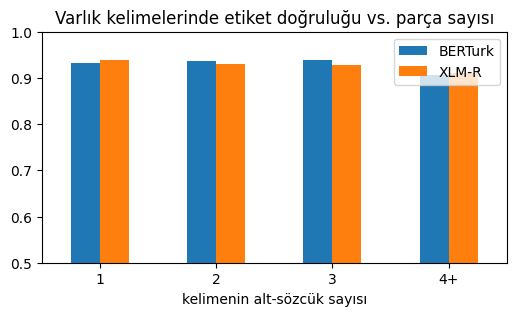

In [ ]:
def pieces_for_test(tok):
    toks = list(dsd["test"]["tokens"])
    enc = tok(toks, is_split_into_words=True, truncation=True, max_length=MAX_LEN)
    out = []
    for i in range(len(toks)):
        wids = enc.word_ids(i); cnt = Counter(w for w in wids if w is not None)
        seen, order = set(), []
        for w in wids:
            if w is not None and w not in seen:
                seen.add(w); order.append(w)
        out.append([cnt[w] for w in order])
    return out

def bucket_acc(tp, tl, pieces):
    rows = []
    for p, l, n in zip(tp, tl, pieces):
        for a, b, c in zip(p, l, n):
            if b != "O":
                rows.append((min(c, 4), a == b))
    df = pd.DataFrame(rows, columns=["parça", "doğru"])
    return df.groupby("parça")["doğru"].agg(["mean", "count"])

b1 = bucket_acc(tp1, tl1, pieces_for_test(tok1))
b2 = bucket_acc(tp2, tl2, pieces_for_test(tok2))
bk = pd.concat({"BERTurk": b1, "XLM-R": b2}, axis=1)
bk.index = [str(i) if i < 4 else "4+" for i in bk.index]
display(bk.round(3))
bk.xs("mean", axis=1, level=1).plot(kind="bar", figsize=(6, 3), title="Varlık kelimelerinde etiket doğruluğu vs. parça sayısı", ylim=(0.5, 1))
plt.xlabel("kelimenin alt-sözcük sayısı"); plt.xticks(rotation=0); plt.show()

### 9.2 İki modelin ayrıştığı cümleler (hata analizi)

In [ ]:
test_tokens = dsd["test"]["tokens"]
shown = 0
for i, (a, b, g) in enumerate(zip(tp1, tp2, tl1)):
    if a != b and len(a) == len(b) == len(g) == len(test_tokens[i]) and (a != g or b != g):
        diff = [(w, gg, x, y) for w, gg, x, y in zip(test_tokens[i], g, a, b) if not (gg == x == y)]
        print(f"Cümle: {' '.join(test_tokens[i])}")
        print(pd.DataFrame(diff, columns=["kelime", "gerçek", "BERTurk", "XLM-R"]).to_string(index=False))
        print("-" * 70)
        shown += 1
    if shown >= 6:
        break

Cümle: Nüfusunun büyük çoğunluğunu Türkmenler oluşturmaktadır .
    kelime gerçek BERTurk XLM-R
Türkmenler  B-ORG   B-ORG B-LOC
----------------------------------------------------------------------
Cümle: Perşembe , uzun zaman Roma ve Bizans hakimiyetinde kalmıştır .
  kelime gerçek BERTurk XLM-R
Perşembe      O   B-LOC     O
----------------------------------------------------------------------
Cümle: `` All I Have '' ( LL Cool J ile düet )
kelime gerçek BERTurk XLM-R
  Cool  I-PER   I-ORG I-PER
----------------------------------------------------------------------
Cümle: Çanakkale ile ilgili iki yasa teklifi , iki TBMM Araştırma önergesi , otuz dört yazılı , iki sözlü soru önergesi vererek Çanakkale’nin sorunlarını TBMM’ye taşıdı .
   kelime gerçek BERTurk XLM-R
Araştırma      O       O I-ORG
----------------------------------------------------------------------
Cümle: ''Murat Sarsılmaz '' İstanbul'da dünyaya gelmiştir .
   kelime gerçek BERTurk XLM-R
Sarsılmaz      O   I-PER     O


### 9.3 Aynı örnek metinlerde iki model yan yana

In [ ]:
challenge = samples + [
    "Cumhurbaşkanı Ankara'da Alman Başbakan Olaf Scholz ile görüştü.",
    "Ege Üniversitesi'ndeki toplantıya Ahmet Hoca da katıldı.",
]
for s in challenge:
    print("Metin   :", s)
    print("BERTurk :", annotate(s, pipe1(s)))
    print("XLM-R   :", annotate(s, pipe2(s)))
    print()

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Metin   : Mustafa Kemal Atatürk 1881 yılında Selanik'te doğdu.
BERTurk : [Mustafa Kemal Atatürk | PER 1.00] 1881 yılında [Selanik | LOC 1.00]'te doğdu.
XLM-R   : [Mustafa Kemal Atatürk | PER 1.00] 1881 yılında [Selanik | LOC 0.97]'te doğdu.

Metin   : Türkiye Büyük Millet Meclisi Ankara'da toplandı.
BERTurk : [Türkiye Büyük Millet Meclisi | ORG 1.00] [Ankara | LOC 1.00]'da toplandı.
XLM-R   : [Türkiye Büyük Millet Meclisi | ORG 0.99] [Ankara | LOC 1.00]'da toplandı.

Metin   : Hacettepe Üniversitesi'nden mezun olan Ayşe Yılmaz, Google'ın İstanbul ofisinde çalışıyor.
BERTurk : [Hacettepe Üniversitesi | ORG 1.00]'nden mezun olan [Ayşe Yılmaz | PER 0.69], [Google | ORG 0.99]'ın [İstanbul | LOC 0.89] ofisinde çalışıyor.
XLM-R   : [Hacettepe Üniversitesi | ORG 0.98]'nden mezun olan [Ayşe Yılmaz | PER 1.00], [Google | ORG 0.94]'ın [İstanbul | LOC 0.99] ofisinde çalışıyor.

Metin   : Orhan Pamuk, Nobel Edebiyat Ödülü'nü aldıktan sonra Beşiktaş'taki evine döndü.
BERTurk : [Orhan Pamuk | PER 1.

In [ ]:
# Otomatik özet
w = cmp["Test F1"].idxmax()
d = abs(cmp["Test F1"].iloc[0] - cmp["Test F1"].iloc[1])
print(f"Test F1'e göre daha iyi model: {w}  (fark: {d*100:.2f} F1 puanı)")
print(f"Fertility: BERTurk={cmp['Fertility'].iloc[0]}  XLM-R={cmp['Fertility'].iloc[1]}")
print("Not: Tek seed ile elde edilen ~0.5 puandan küçük farklar gürültü olabilir; emin olmak için farklı seed'lerle tekrarlayın.")

Test F1'e göre daha iyi model: XLM-R base  (fark: 0.19 F1 puanı)
Fertility: BERTurk=1.638  XLM-R=1.638
Not: Tek seed ile elde edilen ~0.5 puandan küçük farklar gürültü olabilir; emin olmak için farklı seed'lerle tekrarlayın.


## 10. Sonuçların Yorumlanması (kendi sayılarınızla tamamlayın)

Hücreleri çalıştırdıktan sonra aşağıdaki soruları tablolardaki sayılara bakarak yanıtlayın:

1. **Hangi model daha yüksek test F1 verdi?** Precision–recall dengesi nasıl? (Biri yüksek precision/düşük recall ise "temkinli", tersi ise "cömert" tahmin yapıyor demektir.)
2. **Tip bazında fark:** `ORG` genellikle en zor tiptir (sınırları belirsiz, çok sözcüklü: *Türkiye Büyük Millet Meclisi*) ve `PER`/`LOC`'tan düşük F1 beklenir. Sizin sonuçlarınızda öyle mi?
3. **Tokenizer etkisi:** Fertility tablosu ve "parça sayısına göre doğruluk" grafiği, çok parçalı kelimelerde doğruluğun düştüğünü gösteriyor mu? Türkçe'ye özel WordPiece mi, çok dilli SentencePiece mi kelimeleri daha az bölüyor?
4. **Derlem etkisi:** Türkçe'ye özel küçük derlem ile çok dilli büyük derlem arasında fark var mı? Büyük çok dilli model her dilde "kapasitesini paylaşırken", tek dilli model Türkçe morfolojisine odaklanabilir; fakat XLM-R'in daha büyük ve daha uzun ön-eğitimi tersini de sağlayabilir.
5. **Strateji etkisi:** Model 2'de LLRD + donuk embedding + cosine kullanıldı. Model farkı mimari/derlemden mi, stratejiden mi geliyor? Kesin ayırmak için **çapraz deney** yapın: BERTurk'ü Strateji B ile, XLM-R'ı Strateji A ile eğitip dört hücreli bir tablo çıkarın (`run_experiment` parametrelerini değiştirmeniz yeterli).
6. **Sınırlılıklar:** WikiANN etiketleri otomatik üretilmiştir (gürültülü), tek seed kullanıldı, yalnızca üç varlık tipi var.

In [ ]:
# (İsteğe bağlı) Modelleri kaydet
# trainer1.save_model("ner_berturk_tr"); tok1.save_pretrained("ner_berturk_tr")
# trainer2.save_model("ner_xlmr_tr");    tok2.save_pretrained("ner_xlmr_tr")